# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [1]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [2]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [3]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:55308/'

## Task 1: Collect the Orders

The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

- `order_id`, the identifier of the order,
- `restaurant`, `cuisine`, and `city`,
- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
- `minutes`, the minutes the delivery took,
- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [4]:
# Write your solution here.

## REQUEST

response = requests.get(urljoin(BASE, "catalogue/page-1.html"), timeout=10)
response.status_code

200

In [5]:
response.raise_for_status()
response.headers["Content-Type"], len(response.content)

('text/html; charset=utf-8', 13031)

In [6]:
print(response.text[:512])

<!doctype html>
<html lang="en">

<head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <title>Delivered orders, page 1 | City Delivery</title>
    <link rel="stylesheet" href="../assets/site.css">
</head>

<body>
    <header class="site-header">
        <div class="wrap"><a class="brand" href="../index.html">City Delivery</a>
            <nav class="primary-nav" aria-label="Main"><a href="../index.html">Home</a><a
                    href="../catalog


In [ ]:
## GET CARDS

soup = BeautifulSoup(response.text, "lxml")
cards = soup.select("article.order")
first = cards[0]
len(cards), first["data-id"]

(12, '310069')

In [ ]:
## TEST AND RAW PARSE ONE CARD

{
    "order_id": first["data-id"],
    "restaurant": first.select_one(".title").get_text(),
    "cuisine": first.select_one(".place .cuisine").get_text(),
    "city": first.select_one(".place .city").get_text(),
    "distance": first.select_one(".summary").get_text(),  # regex
    "unit": first.select_one(".summary").get_text(),  # regex
    "minutes": first.select_one(".delivery").get_text(),
    "slot": first.select_one(".tags .slot").get_text(),
    "weather": first.select_one(".tags .weather").get_text(),
    "payment": first.select_one(".tags .payment").get_text(),
    "rating": first.select_one(".tags .rating").get_text(),
    "by_restaurant": first.select_one(
        ".courier"
    ).get_text(),  # true = delivered by own, false = delivered by a courier
}

{'order_id': '310069',
 'restaurant': 'Salad Bowl',
 'cuisine': 'Salad',
 'city': 'Skopje',
 'distance': 'A trip of 5.0 km from the restaurant to the door.',
 'unit': 'A trip of 5.0 km from the restaurant to the door.',
 'minutes': 'Delivered in 23 minutes.',
 'slot': 'Late night',
 'weather': 'Clear',
 'payment': 'Cash',
 'rating': 'Rated 5 of 5',
 'by_restaurant': 'Delivered by a City Delivery courier.'}

In [169]:
## EXTRACT INFORMATION BASED ON RULES AND REGEX

DISTANCE_REGEX = re.compile(
    r"A trip of ([\d.]+(?:\s\d+)*) (km|m|mi|miles|meters|kilometers) from the restaurant to the door."
)
MINUTES_REGEX = re.compile(r"Delivered in (\d+) minutes.")
RATING_REGEX = re.compile(r"Rated (\d+) of (\d+)")

# text = "A trip of 5.0 km from the restaurant to the door."
# text_2 = "Delivered in 23 minutes."
# text_3 = "Rated 5 of 5"
# re.search(DISTANCE_REGEX,text).groups()
# re.search(MINUTES_REGEX, text_2).groups()[0]
# re.search(RATING_REGEX, text_3).groups()


def required_text(card: Tag, selector: str) -> str:
    element = card.select_one(selector)
    if element is None:
        raise ValueError(f"Order {card['data-id']} has no {selector} element.")
    return element.get_text(strip=True)


def optional_text(card: Tag, selector: str) -> str | None:
    element = card.select_one(selector)
    return element.get_text(strip=True) if element else None


def captures(pattern: re.Pattern[str], text: str) -> tuple[str, ...]:
    match = pattern.search(text)
    if match is None:
        raise ValueError(f"{text!r} does not match {pattern.pattern!r}.")
    return match.groups()


def parse_order(card: Tag) -> dict[str, object]:
    distance, unit = captures(DISTANCE_REGEX, required_text(card, ".summary"))
    
    delivery_text = optional_text(card, ".delivery.figure")
    minutes = (
        int(captures(MINUTES_REGEX, delivery_text)[0])
        if delivery_text is not None
        else None
    )

    rating_text = optional_text(card, ".tags .rating")
    rating = (
        int(captures(RATING_REGEX, rating_text)[0])
        if rating_text is not None
        else None
    )
    
    by_restaurant = required_text(card, ".courier").endswith("restaurant.")
    
    return {
        "order_id": int(card["data-id"]),
        "restaurant": required_text(card, ".title"),
        "cuisine": required_text(card, ".place .cuisine"),
        "city": required_text(card, ".place .city"),
        "distance": float(distance.replace(" ", "")),  # regex
        "unit": str(unit),  # regex
        "minutes": minutes, # regex
        "slot": optional_text(card, ".tags .slot"),
        "weather": optional_text(card, ".tags .weather"),
        "payment": optional_text(card, ".tags .payment"),
        "rating": rating,
        "by_restaurant": by_restaurant # True = delivered by restaurant itself, False = delivered by an external courier
    }
parse_order(cards[2])

{'order_id': 832866,
 'restaurant': 'Sushi Bar',
 'cuisine': 'Sushi',
 'city': 'Skopje',
 'distance': 4700.0,
 'unit': 'm',
 'minutes': None,
 'slot': 'Lunch',
 'weather': 'Rain',
 'payment': 'Cash',
 'rating': 3,
 'by_restaurant': True}

In [170]:
## PAGINATION

records, url, pages = [], urljoin(BASE, "catalogue/page-1.html"), 0
while url:
    page = requests.get(url, timeout=10)
    page.raise_for_status()
    soup = BeautifulSoup(page.text, "lxml")
    records += [
        parse_order(card) for card in soup.select("article.order")
    ]
    link = soup.select_one("a.next")
    url = urljoin(url, link["href"]) if link else None
    pages += 1

orders = pd.DataFrame(records)
pages, orders.shape

(16, (192, 12))

In [171]:
orders.head()

,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True


## Task 2: Add the Receipts

The home page of the service, `index.html` under `BASE`, points to a page of receipts. Collect every receipt the page holds, and add the items, the total, and the tip of each order to `orders`, so that every order appears exactly once. Name the result `df`.

Report how many receipts the page says it holds, how many you collected, and what you did about any receipt that would put an order in `df` more than once.

In [172]:
# Write your solution here.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    tab = await browser.new_page()
    await tab.goto(urljoin(BASE, "receipts.html"))
    await tab.wait_for_selector("#receipts td")
    rendered = await tab.content()
    await browser.close()

rows = BeautifulSoup(rendered, "lxml").select("#receipts tr:has(td)")
receipts = pd.DataFrame(
    [
        {
            "order_id" : int(row.select_one(".order-id").get_text()),
            "items": int(row.select_one(".items").get_text()),
            "total": int(row.select_one(".total").get_text()),
            "tip": int(row.select_one(".tip").get_text()),
        }
        for row in rows
    ]
)
receipts

,order_id,items,total,tip
0,695291,3,870,100
1,893046,3,740,0
2,797860,3,640,50
3,294233,3,1180,260
4,466129,2,430,10
...,...,...,...,...
188,743156,4,1070,100
189,134759,3,1350,110
190,885138,3,930,40
191,933751,1,420,20


The page says that it holds 193 receipts, the collected receipts match the stated number:

In [173]:
receipts.shape

(193, 4)

Trying to join the `orders` and `receipts` dataframes

In [174]:
try:
    orders.merge(receipts, on="order_id", validate="one_to_one")
except pd.errors.MergeError as error:
    print(error)

Merge keys are not unique in right dataset; not a one-to-one merge
Duplicates in right:
  order_id
   510546 ...


There are two duplicates in `receipts` dataframe:

In [175]:
receipts[receipts.duplicated("order_id", keep=False)]

,order_id,items,total,tip
99,510546,4,1180,0
100,510546,4,1180,0


Droping the duplicate row in `receipts` dataframe and then join:

In [176]:
receipts = receipts.drop_duplicates()
df = orders.merge(
    receipts, on="order_id", how="left", validate="one_to_one", indicator=True
)
df['_merge'].value_counts()

_merge
both          192
left_only       0
right_only      0
Name: count, dtype: int64

After removing the duplicates from `receipts` dataframe there are 192 items instead of 193.

In [177]:
receipts.shape

(192, 4)

The obtained dataframe after merging:

In [178]:
df.head()

,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip,_merge
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False,2,770,0,both
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False,4,860,60,both
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True,2,710,0,both
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False,3,1240,60,both
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True,2,450,30,both


In [179]:
df = df.drop(columns="_merge")
df.shape

(192, 15)

In [180]:
df

,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False,2,770,0
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False,4,860,60
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True,2,710,0
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False,3,1240,60
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True,2,450,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,120901,Sushi Bar,Sushi,Tetovo,1200.0,m,NaN,Dinner,Clear,Cash,4.0,True,4,840,0
188,463435,Salad Bowl,Salad,Skopje,4.1,km,36.0,Late night,Clear,Cash,5.0,False,2,750,0
189,951424,City Grill,Grill,Skopje,3.2,km,21.0,Late night,Clear,Card,4.0,True,2,460,50
190,838472,Home Kitchen,Traditional,Skopje,1.5,km,34.0,Dinner,Clear,Cash,4.0,False,2,780,100


## Task 3: Describe the Orders

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The slots have a natural order, from lunch to late night, and the type of `slot` keeps it.

In [181]:
# Write your solution here.
df["slot"].value_counts()

slot
Dinner        79
Late night    57
Lunch         56
Name: count, dtype: int64

In [182]:
for column in [
    "order_id",
    "minutes",
    "rating",
    "items",
    "total",
    "tip",
]:
    df[column] = df[column].astype("Int64")

for column in ["cuisine", "city", "unit", "weather", "payment"]:
    df[column] = df[column].astype("category")

df.dtypes

order_id            Int64
restaurant            str
cuisine          category
city             category
distance          float64
unit             category
minutes             Int64
slot                  str
weather          category
payment          category
rating              Int64
by_restaurant        bool
items               Int64
total               Int64
tip                 Int64
dtype: object

Convert `slot` into ordered category `Lunch < Dinner < Night` 

In [198]:
slot_order = ["Lunch", "Dinner", "Late night"]
df["slot"] = pd.Categorical(
    df["slot"],
    categories=slot_order,
    ordered=True
)
df["by_restaurant"] = df["by_restaurant"].astype("boolean")
df.dtypes

order_id            Int64
restaurant            str
cuisine          category
city             category
distance          float64
unit             category
minutes             Int64
slot             category
weather          category
payment          category
rating              Int64
by_restaurant     boolean
items               Int64
total               Int64
tip                 Int64
dtype: object

In [199]:
df.head()

,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23,Late night,Clear,Cash,5,False,2,770,0
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30,Lunch,Clear,Card,3,False,4,860,60
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,<NA>,Lunch,Rain,Cash,3,True,2,710,0
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25,Lunch,Rain,Card,4,False,3,1240,60
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26,Late night,Clear,Card,4,True,2,450,30


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

In [201]:
# Write your solution here.
df.isna().sum()[lambda counts: counts > 0]

minutes    42
rating     24
dtype: int64

`by_restaurant` is the candidate for `minutes`: an order that the restaurant delivered itself may not report a duration. Sorting the orders by that column puts the restaurant delivered orders on the left.

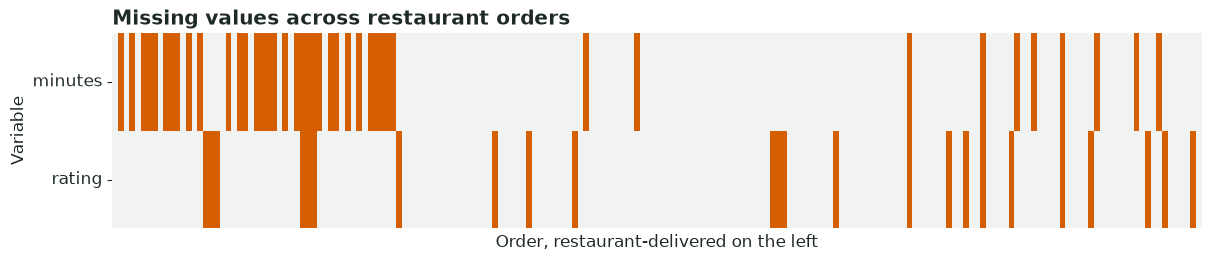

In [211]:
ordered = df.sort_values("by_restaurant", ascending=False)
missing_map = ordered[["minutes", "rating"]].isna().T

fig, ax = plt.subplots(figsize=(12, 2.5))
sns.heatmap(
    missing_map,
    cbar=False,
    cmap=["#f1f3f2", PALETTE[1]],
    xticklabels=False,
    ax=ax,
)
ax.set(
    title="Missing values across restaurant orders",
    xlabel="Order, restaurant-delivered on the left",
    ylabel="Variable",
)
ax.tick_params(axis="y", rotation=0)
plt.show()

The `minutes` gaps gather among the restaurant delivered orders, while the `rating` gaps scatter across both sides. The tables below count the two groups.

In [212]:
pd.crosstab(
    df["by_restaurant"],
    df["minutes"].isna().rename("minutes missing"),
).rename(
    index={False: "City Delivery courier", True: "Restaurant"},
    columns={False: "Present", True: "Missing"},
)

minutes missing,Present,Missing
by_restaurant,,
City Delivery courier,132,10
Restaurant,18,32


Share table for minutes

In [213]:
by_courier = (
    df["minutes"]
    .isna()
    .groupby(df["by_restaurant"], observed=True)
    .agg(missing="sum", orders="size", share="mean")
    .rename(index={False: "City Delivery courier", True: "Restaurant"})
)
by_courier.round(2)

,missing,orders,share
by_restaurant,,,
City Delivery courier,10,142,0.07
Restaurant,32,50,0.64


`rating` has no candidate that separates the gaps as sharply. Crossing it with `weather`, `payment`, and the delivery arrangement shows only small differences.

In [214]:
by_weather = (
    df["rating"]
    .isna()
    .groupby(df["weather"], observed=True)
    .agg(missing="sum", orders="size", share="mean")
)
by_weather.round(2)

,missing,orders,share
weather,,,
Clear,13,134,0.10
Rain,11,58,0.19


In [215]:
by_payment = (
    df["rating"]
    .isna()
    .groupby(df["payment"], observed=True)
    .agg(missing="sum", orders="size", share="mean")
)
by_payment.round(2)

,missing,orders,share
payment,,,
Card,19,140,0.14
Cash,5,52,0.10


In [216]:
by_courier_rating = (
    df["rating"]
    .isna()
    .groupby(df["by_restaurant"], observed=True)
    .agg(missing="sum", orders="size", share="mean")
    .rename(index={False: "City Delivery courier", True: "Restaurant"})
)
by_courier_rating.round(2)

,missing,orders,share
by_restaurant,,,
City Delivery courier,18,142,0.13
Restaurant,6,50,0.12


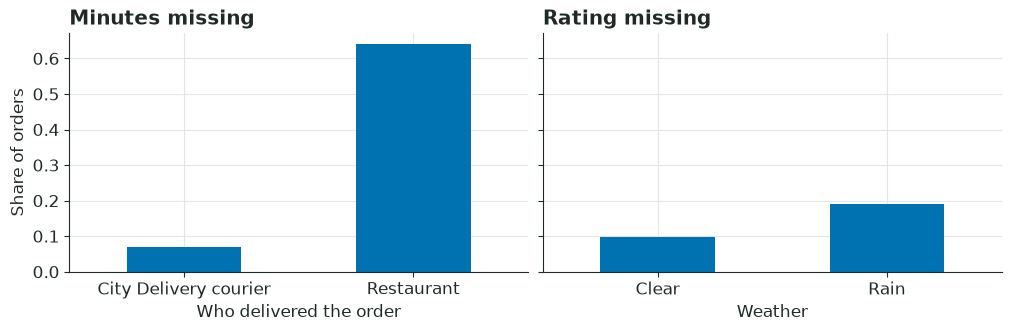

In [217]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)

by_courier["share"].plot.bar(
    ax=axes[0], rot=0, title="Minutes missing"
)
axes[0].set_xlabel("Who delivered the order")
axes[0].set_ylabel("Share of orders")

by_weather["share"].plot.bar(
    ax=axes[1], rot=0, title="Rating missing"
)
axes[1].set_xlabel("Weather")
plt.show()

The two columns with gaps behave differently:

- `minutes` is missing for 42 of 192 orders (21.9%). Its absence follows `by_restaurant`: 32 of 50 restaurant delivered orders (64%) lack it, against 10 of 142 courier-delivered orders (7%). The field appears not to be recorded when the restaurant delivers the order itself, so the gap is tied to the delivery arrangement rather than scattered at random.
- `rating` is missing for 24 of 192 orders (12.5%). No observed column separates the gaps sharply: 19% for rain against 10% for clear weather, 14% for card against 10% for cash, and 13% for restaurant delivery against 12% for courier delivery. These differences are small and the groups are uneven, so the rating gaps look scattered rather than explained by another column.

The map shows association, not a cause: the data alone cannot confirm why a field was left out. The practical consequence is that dropping every row with a missing value would remove 32 of the 50 restaurant-delivered orders, which would bias a comparison of delivery times. The rating gaps are spread more evenly, so dropping them loses less of any one group, but the choice still has to be made deliberately.

### 3.3 Distances in Two Units

Some orders quote the distance in metres and others in kilometres. Compare the quoted distances within each unit, then add a column `distance_km` that states every distance in kilometres.

In [218]:
df.head()

,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23,Late night,Clear,Cash,5,False,2,770,0
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30,Lunch,Clear,Card,3,False,4,860,60
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,<NA>,Lunch,Rain,Cash,3,True,2,710,0
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25,Lunch,Rain,Card,4,False,3,1240,60
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26,Late night,Clear,Card,4,True,2,450,30


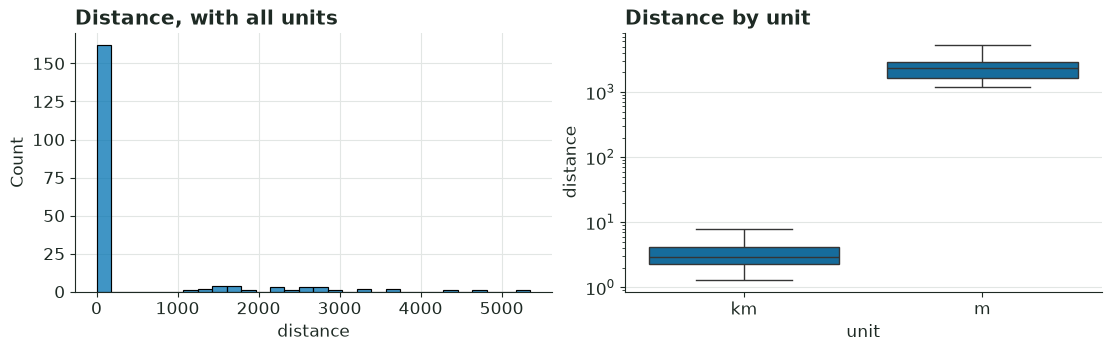

In [220]:
# Write your solution here.

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(df, x="distance", bins=30, ax=axes[0])
axes[0].set_title("Distance, with all units")
sns.boxplot(df, x="unit", y="distance", ax=axes[1], log_scale=True)
axes[1].set_title("Distance by unit")
plt.show()


In [222]:
pooled = pd.DataFrame(
    {
        "count": [len(df)],
        "median": [df["distance"].median()],
        "skew": [df["distance"].skew()],
    },
    index=pd.Index(["pooled"], name="distance"),
)
by_distance = df.groupby("unit", observed=True)["distance"].agg(
    ["count", "median", "skew"]
)
pd.concat([pooled, by_distance]).round(2)

,count,median,skew
pooled,192,3.2,2.72
km,162,2.9,0.84
m,30,2375.0,1.02


In [224]:
M_PER_KM = 1000
df["distance_km"] = df["distance"].where(df["unit"] == "km", df["distance"] / M_PER_KM)
df

,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip,distance_km
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23,Late night,Clear,Cash,5,False,2,770,0,5.00
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30,Lunch,Clear,Card,3,False,4,860,60,3.65
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,<NA>,Lunch,Rain,Cash,3,True,2,710,0,4.70
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25,Lunch,Rain,Card,4,False,3,1240,60,2.70
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26,Late night,Clear,Card,4,True,2,450,30,2.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,120901,Sushi Bar,Sushi,Tetovo,1200.0,m,<NA>,Dinner,Clear,Cash,4,True,4,840,0,1.20
188,463435,Salad Bowl,Salad,Skopje,4.1,km,36,Late night,Clear,Cash,5,False,2,750,0,4.10
189,951424,City Grill,Grill,Skopje,3.2,km,21,Late night,Clear,Card,4,True,2,460,50,3.20
190,838472,Home Kitchen,Traditional,Skopje,1.5,km,34,Dinner,Clear,Cash,4,False,2,780,100,1.50


### 3.4 The Delivery Time

Describe the delivery time by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical order better.

In [226]:
# Write your solution here.

def centre_and_spread(values: pd.Series) -> pd.Series:
    q1, q3 = values.quantile([0.25, 0.75])
    return pd.Series(
        {
            "mean": values.mean(),
            "median": values.median(),
            "range": values.max() - values.min(),
            "variance": values.var(),
            "std": values.std(),
            "Q1": q1,
            "Q3": q3,
            "IQR": q3 - q1,
        }
    )


pd.DataFrame(
    {"minutes": centre_and_spread(df["minutes"])}
).round(1)

,minutes
mean,29.8
median,27.0
range,60.0
variance,105.8
std,10.3
Q1,23.0
Q3,34.0
IQR,11.0


The median and IQR describe a typical delivery better than the mean and standard deviation. The median is 27 min with an IQR of 11 min; the mean is 29.8 min and the standard deviation 10.3 min, inflated by the long right tail. The central half of orders takes 23–34 min, while a few orders take over an hour.

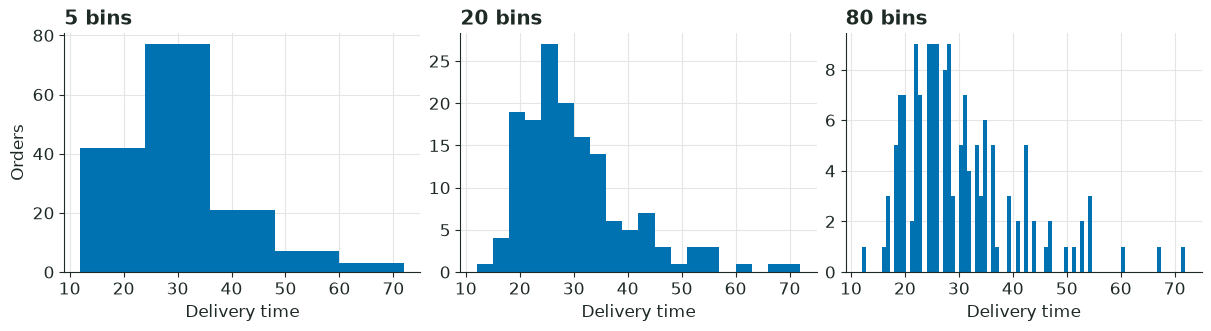

In [228]:
# Distribution with histogram
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for ax, bins in zip(axes, [5, 20, 80]):
    ax.hist(df["minutes"], bins=bins)
    ax.set(title=f"{bins} bins", xlabel="Delivery time")
axes[0].set_ylabel("Orders")
plt.show()

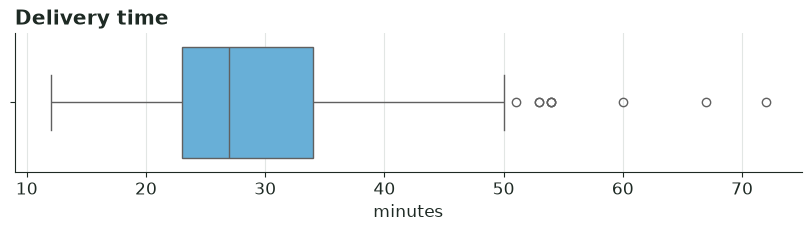

In [229]:
fig, ax = plt.subplots(figsize=(8, 2.2))
sns.boxplot(df, x="minutes", ax=ax, color=PALETTE[5])
ax.set_title("Delivery time")
plt.show()

### 3.5 Delivery Time by Slot

Compare the delivery time across the slots.

In [230]:
by_slot = (
    df.groupby("slot", observed=True)["minutes"]
    .agg(
        orders="size",
        observed="count",
        Q1=lambda values: values.quantile(0.25),
        median="median",
        Q3=lambda values: values.quantile(0.75),
        maximum="max",
        mean="mean",
        std="std",
        skew="skew",
    )
)
by_slot["missing"] = by_slot["orders"] - by_slot["observed"]
by_slot["IQR"] = by_slot["Q3"] - by_slot["Q1"]
by_slot = by_slot[
    [
        "orders",
        "missing",
        "observed",
        "Q1",
        "median",
        "Q3",
        "IQR",
        "mean",
        "std",
        "skew",
        "maximum",
    ]
]
by_slot.round(1)

,orders,missing,observed,Q1,median,Q3,IQR,mean,std,skew,maximum
slot,,,,,,,,,,,
Lunch,56,11,45,23.0,27.0,31,8.0,28.9,9.6,1.1,54
Dinner,79,18,61,24.0,28.0,35,11.0,30.8,9.5,0.7,54
Late night,57,13,44,22.8,26.0,32,9.2,29.3,12.0,2.2,72


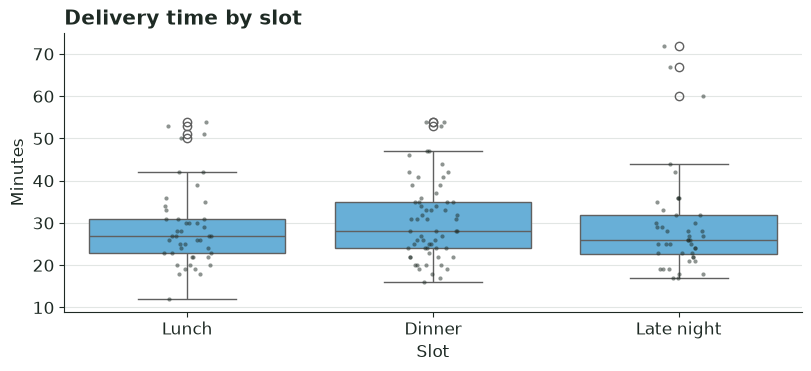

In [233]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(df, x="slot", y="minutes", ax=ax, color=PALETTE[5])
sns.stripplot(
    df,
    x="slot",
    y="minutes",
    ax=ax,
    color=INK,
    size=3,
    alpha=0.5,
)
ax.set(
    title="Delivery time by slot",
    xlabel="Slot",
    ylabel="Minutes",
)
plt.show()

Delivery times are similar at the centre across slots: median 27 min at lunch, 28 min at dinner, and 26 min late at night. Dinner is the slowest typical slot and has the widest middle half (Q1–Q3 24–35 min, IQR 11 min). Late night is slightly faster typically but has the heaviest tail: its mean (29.3 min) is above lunch’s (28.9 min) even though its median is lower, and its maximum is 72 min. Lunch is in between. Missing times are similar across slots, about 20–23%, so no single slot dominates the missingness, but the comparison still describes only the 45, 61, and 44 orders with a recorded time.

### 3.6 Orders by City

Show how the orders are spread across the cities, and give the share of orders in each city.

In [234]:
# Write your solution here.
city_summary = pd.DataFrame(
    {
        "orders": df["city"].value_counts(),
        "share": df["city"].value_counts(normalize=True),
    }
)
city_summary["share_pct"] = (100 * city_summary["share"]).round(1)
city_summary

,orders,share,share_pct
city,,,
Skopje,99,0.515625,51.6
Tetovo,24,0.125000,12.5
Kumanovo,22,0.114583,11.5
Bitola,18,0.093750,9.4
Ohrid,15,0.078125,7.8
Prilep,14,0.072917,7.3


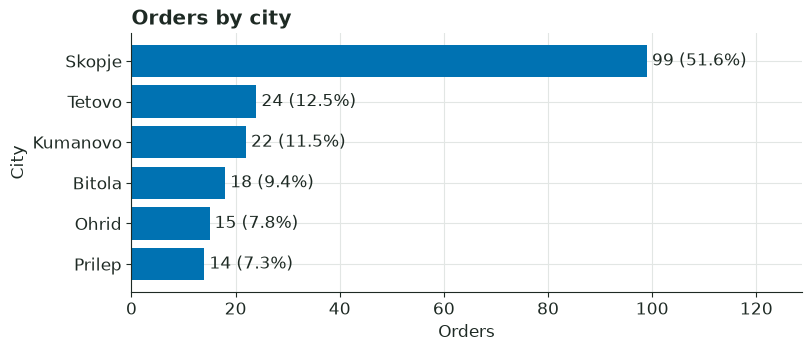

In [235]:
by_city = city_summary.sort_values("orders")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(
    by_city.index.astype(str),
    by_city["orders"],
    color=PALETTE[0],
)

for position, (orders, share) in enumerate(
    zip(by_city["orders"], by_city["share"])
):
    ax.text(
        orders,
        position,
        f" {orders} ({share:.1%})",
        va="center",
    )

ax.set_xlim(0, by_city["orders"].max() * 1.3)
ax.set(
    title="Orders by city",
    xlabel="Orders",
    ylabel="City",
)
plt.show()

The orders are concentrated in Skopje: 99 of 192 orders, or 51.6%. Skopje alone accounts for slightly more than all the other cities combined (99 against 93). The remaining cities hold between 14 and 24 orders each: Tetovo 24 (12.5%), Kumanovo 22 (11.5%), Bitola 18 (9.4%), Ohrid 15 (7.8%), and Prilep 14 (7.3%). Because city is complete for all 192 orders, these shares describe the whole table rather than only orders with a recorded delivery time.

### 3.7 Items and Total

Show how the number of items and the total of an order move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

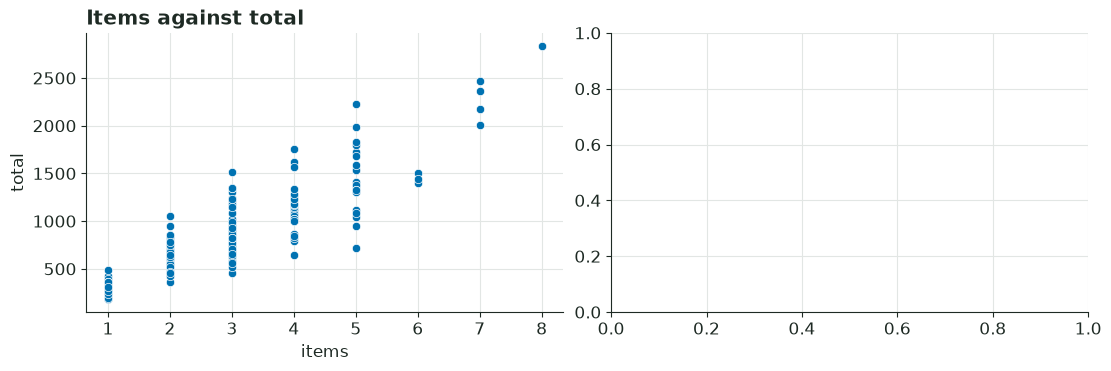

In [238]:
# Write your solution here.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.scatterplot(df, x="items", y="total", ax=axes[0])
axes[0].set_title("Items against total")
plt.show()

In [239]:
pairs = [("items", "total")]
pd.DataFrame(
    {
        "pearson": [df[a].corr(df[b]) for a, b in pairs],
        "spearman": [df[a].corr(df[b], method="spearman") for a, b in pairs],
    },
    index=[f"{a} and {b}" for a, b in pairs],
).round(2)

,pearson,spearman
items and total,0.88,0.87


The relationship is strong, positive, and close to a straight line. Pearson 0.88 and Spearman 0.87 nearly agree.

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

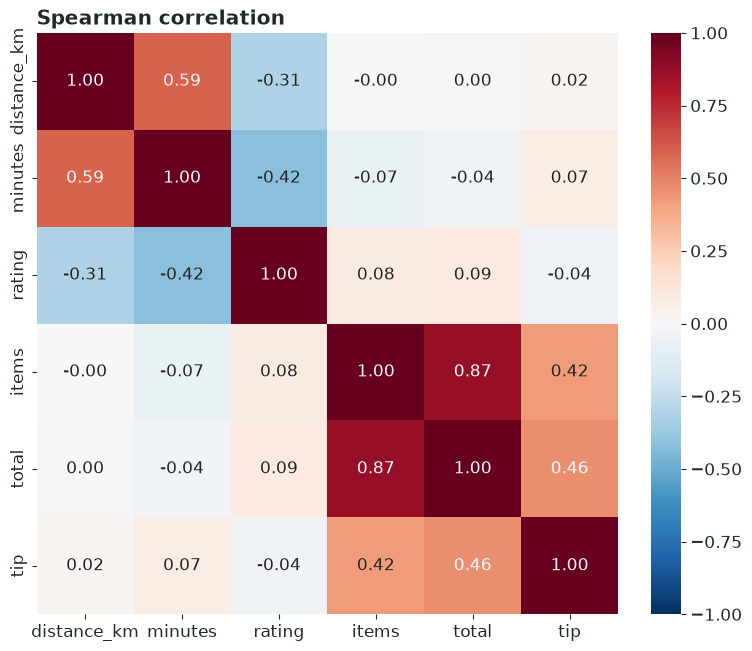

In [251]:
# Write your solution here.
numeric = [
    "distance_km",
    "minutes",
    "rating",
    "items",
    "total",
    "tip",
]

spearman = df[numeric].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.4))
sns.heatmap(
    spearman,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title("Spearman correlation")
plt.show()

In [252]:
pairs = pd.DataFrame(
    [
        {"first": first, "second": second, "spearman": spearman.loc[first, second]}
        for i, first in enumerate(numeric)
        for second in numeric[i + 1:]
    ]
)
pairs["strength"] = pairs["spearman"].abs()
pairs.sort_values("strength", ascending=False).head()

,first,second,spearman,strength
12,items,total,0.869127,0.869127
0,distance_km,minutes,0.589610,0.589610
14,total,tip,0.463362,0.463362
13,items,tip,0.422834,0.422834
5,minutes,rating,-0.415339,0.415339


 The strongest pair is items and total, with a Spearman correlation of 0.87. The next strongest is distance_km and minutes (0.59): longer trips tend to take longer. Ratings fall slightly as delivery time rises (−0.42).

### 3.9 Delivery Time by City and Slot

Find the combination of city and slot with the highest median delivery time, counting only the combinations with at least three orders that state a delivery time.

In [253]:
# Write your solution here.
by_city_slot = (
    df.groupby(["city", "slot"], observed=True)["minutes"]
    .agg(
        orders="size",
        observed="count",
        median="median",
    )
    .loc[lambda table: table["observed"] >= 3]
    .sort_values("median", ascending=False)
    .reset_index()
)
by_city_slot

,city,slot,orders,observed,median
0,Prilep,Dinner,6,5,35.0
1,Tetovo,Lunch,4,3,34.0
2,Kumanovo,Dinner,8,6,33.5
3,Tetovo,Late night,8,5,32.0
4,Ohrid,Late night,4,3,32.0
5,Kumanovo,Lunch,8,8,29.5
6,Tetovo,Dinner,12,8,29.5
7,Bitola,Lunch,4,4,28.5
8,Skopje,Dinner,42,35,28.0
9,Prilep,Lunch,5,3,27.0


 Prilep at Dinner has the highest median delivery time

## Task 4: Delivery Times

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the orders that state a delivery time.

### 4.1 The Advertised Time

The home page states an average delivery time. Decide whether the average delivery time of the orders differs from that statement, and give a range for the average delivery time.

---

The Front Page States

Fast delivery
Your food arrives in 28 minutes on average.

In [256]:
# Write your solution here.

# t-test

# Clean data = remove missing values
delivery_time = df["minutes"].dropna()
delivery_time.head()

0    23
1    30
3    25
4    26
5    25
Name: minutes, dtype: Int64

In [259]:
alpha = 0.05
result = stats.ttest_1samp(delivery_time, popmean=28)
result

TtestResult(statistic=np.float64(2.1198825543715145), pvalue=np.float64(0.035672962210614674), df=np.int64(149))

In [260]:
if result.pvalue < alpha:
    print("H_0 is rejected.")
else:
    print("H_0 is not rejected.")

H_0 is rejected.


$H_0$: $\mu = 28$

$H_a: \mu \neq 28$

$p-value = 0.035672962210614674$

$\alpha = 0.05$, since $p-value < 0.05$, $H_0$ is rejected.

In [261]:
# Confidence Interval

ci = result.confidence_interval()
ci

ConfidenceInterval(low=np.float64(28.120802678415576), high=np.float64(31.439197321584427))

In [262]:
print(
    f"Confidence Interval: [{ci.low}, {ci.high}]"
)

Confidence Interval: [28.120802678415576, 31.439197321584427]


### 4.2 Rain and Clear Weather

Decide whether the orders delivered in rain and in clear weather differ in their average delivery time, and give a range for the difference, taken as rain minus clear.

In [270]:
# Write your solution here.

# Welch Test of two means of independent groups

rain = df.loc[df["weather"] == "Rain", "minutes"].dropna()
clear = df.loc[df["weather"] == "Clear", "minutes"].dropna()

welch = stats.ttest_ind(rain, clear, equal_var=False)
welch

TtestResult(statistic=np.float64(2.1960116755389842), pvalue=np.float64(0.031371648323607615), df=np.float64(70.7350841658899))

$H_0: \mu_{rain} = \mu_{clear}$

$H_0: \mu_{rain} \neq \mu_{clear}$

$p-value = 0.0313$, since $p-value < 0.05$, $H_0$ is rejected.

In [271]:
if welch.pvalue < alpha:
    print("H_0 is rejected.")
else:
    print("H_0 is not rejected.")

H_0 is rejected.


In [272]:
ci_welch = welch.confidence_interval()
ci_welch

ConfidenceInterval(low=np.float64(0.3938099768768413), high=np.float64(8.171269388202528))

In [273]:
print(f"CI for Welch: [{ci_welch.low}, {ci_welch.high}]")

CI for Welch: [0.3938099768768413, 8.171269388202528]


In [274]:
weather_summary = (
    df.groupby("weather", observed=True)["minutes"]
    .agg(
        orders="size",
        observed="count",
        mean="mean",
        std="std",
        median="median",
    )
)
weather_summary.round(2)

,orders,observed,mean,std,median
weather,,,,,
Clear,134,105,28.5,9.48,26.0
Rain,58,45,32.78,11.52,31.0


Meaning orders delivered with Rain weather took slower than others with Clear weather

## Task 5: Slots and Payments

The questions of this task concern all orders.

### 5.1 Payment by Slot

Decide whether the payment method depends on the slot of an order, and give a range for the share of cash payments in each slot, using a percentile bootstrap.

In [ ]:
# Write your solution here.

## Chi-square Test of Independence of Categorical Variables

table = pd.crosstab(df["payment"], df["slot"])
results_chi2 = stats.chi2_contingency(table)
table, results_chi2.pvalue, results_chi2.expected_freq.round(1)

(slot     Lunch  Dinner  Late night
 payment                           
 Card        49      57          34
 Cash         7      22          23,
 np.float64(0.003820197333558141),
 array([[40.8, 57.6, 41.6],
        [15.2, 21.4, 15.4]]))

$H_0$: Payment Method and Slot Order are independent

$H_a$: Payment Method and Slot Order are dependent.

In [280]:
if results_chi2.pvalue < alpha:
    print("H_0 is rejected.")
else:
    print("H_0 is not rejected.")

H_0 is rejected.


Meaning Payment Method and Slot are statistically dependent.

In [282]:
## Bootstrap Percentile of Cash Payments

results = []
bootstrap_distributions = {}

for slot, group in df.groupby("slot", observed=True):
    cash = group["payment"].eq("Cash").to_numpy()

    percentile = stats.bootstrap(
        (cash,),
        np.mean,
        n_resamples=9_999,
        method="percentile",
        rng=rng
    )

    bootstrap_distributions[slot] = percentile.bootstrap_distribution

    results.append({
        "slot": slot,
        "cash_share": cash.mean(),
        "low": percentile.confidence_interval.low,
        "high": percentile.confidence_interval.high
    })

summary = pd.DataFrame(results).set_index("slot")
display(summary.round(3))

,cash_share,low,high
slot,,,
Lunch,0.125,0.054,0.214
Dinner,0.278,0.177,0.380
Late night,0.404,0.281,0.526


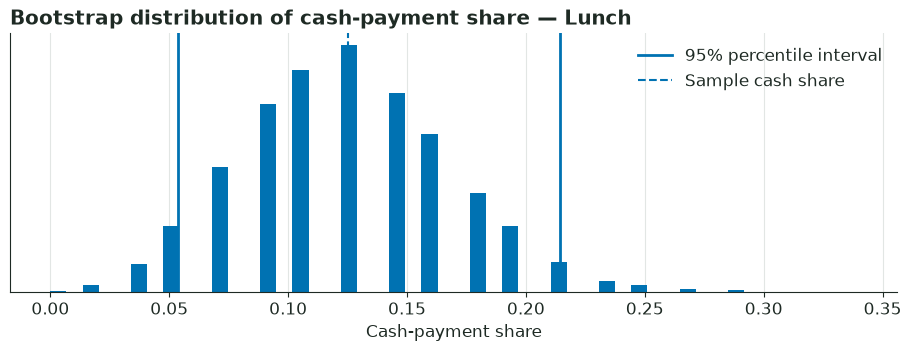

In [ ]:
slot = "Lunch"
cash = df.loc[df["slot"] == slot, "payment"].eq("Cash").to_numpy()
distribution = bootstrap_distributions[slot]
ci = summary.loc[slot, ["low", "high"]]


fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(distribution, bins=50)
ax.axvline(ci["low"], linewidth=2, label="95% percentile interval")
ax.axvline(ci["high"], linewidth=2)
ax.axvline(cash.mean(), linestyle="--", label="Sample cash share")
ax.set(
    title=f"Bootstrap distribution of cash-payment share — {slot}",
    xlabel="Cash-payment share",
    yticks=[]
)
ax.legend()
plt.show()

### 5.2 The Mix of Slots

The home page states how the orders divide among the slots. Decide whether the orders match that statement, and give a range for the share of late-night orders, using a percentile bootstrap.

The Front Page states:

Any time of day
Our orders are 35 % lunch, 45 % dinner, and 20 % late night orders.

$H_0$: The population proportions of orders match the homepage's claim: 35% lunch, 45% dinner, and 20% late night.

or

$H_0$: $p_{lunch}=0.35$ $\land$ $p_{dinner}=0.45$ $\land$ $p_{late_night}=0.20$

$H_a$: The population distribution of orders differs from the homepage's claim; at least one proportion is different..

or

$H_a$: $p_{lunch} \neq 0.35$ $\lor$ $p_{dinner} \neq 0.45$ $\lor$ $p_{late_night} \neq 0.20$

In [288]:
# Write your solution here.

# Chi-square of Goodness-of-fit

observed = df["slot"].value_counts().reindex(
    ["Lunch", "Dinner", "Late night"],
    fill_value=0
)
proportions = np.array([0.35, 0.45, 0.20])
expected = proportions * observed.sum()

result = stats.chisquare(observed, f_exp=expected)
print("Observed counts:")
print(observed)
print("\nExpected counts:")
print(expected)
print(f"\nChi-square statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")

Observed counts:
slot
Lunch         56
Dinner        79
Late night    57
Name: count, dtype: int64

Expected counts:
[67.2 86.4 38.4]

Chi-square statistic: 11.510
p-value: 0.0032


Chi square goodness of fit test provides statistically significant evidence that the observed distribution of orders differs from the homepage's claim.

$p-value < 0.05$

$H_0$ is rejected.

In [289]:
late_night = df["slot"].eq("Late night").to_numpy()

percentile = stats.bootstrap(
    (late_night,),
    np.mean,
    n_resamples=9_999,
    method="percentile",
    rng=np.random.default_rng(42)
)

print(f"\nObserved late-night share: {late_night.mean():.1%}")
print(
    f"95% bootstrap CI: "
    f"[{percentile.confidence_interval.low:.1%}, "
    f"{percentile.confidence_interval.high:.1%}]"
)



Observed late-night share: 29.7%
95% bootstrap CI: [23.4%, 35.9%]


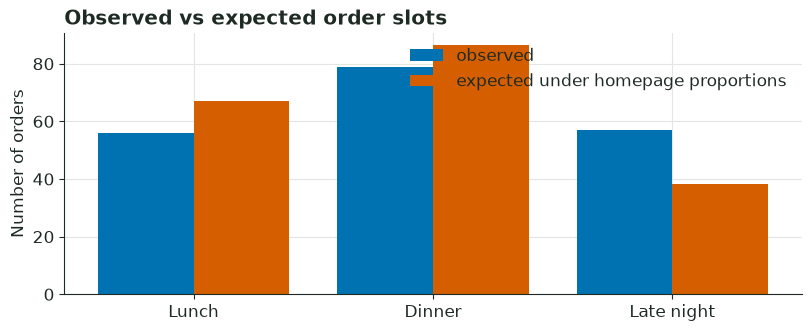

In [290]:
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(observed))

ax.bar(x - 0.2, observed, width=0.4, label="observed")
ax.bar(x + 0.2, expected, width=0.4, label="expected under homepage proportions")

ax.set(
    xticks=x,
    xticklabels=observed.index,
    ylabel="Number of orders",
    title="Observed vs expected order slots"
)
ax.legend()
plt.show()

In [292]:
server.shutdown()